# Numerical exercises 8
The variational principle in Quantum Mechanics states that the expectation value of the Hamiltonian over a (good) trial quantum state has the ground state energy $E_0$ as lower bound:

$$
\langle {\hat H} \rangle_T = 
\frac{\int dx \Psi^*_T(x) {\hat H} \Psi_T(x)}
{\int dx |\Psi_T(x)|^2} \ge E_0 =
\frac{\langle \Psi_0| {\hat H} | \Psi_0 \rangle}
{\langle \Psi_0 | \Psi_0 \rangle}
$$

During this exercise you will variationally optimize the ground state of a single quantum particle in a one dimensional (1D) space confined by the following external potential:
$$
V(x) = x^4 - \frac{5}{2}x^2
$$

This 1D quantum model is not analytically solvable and should be attacked by numerical methods. In order to obtain an approximate wave function for the ground state, the Variational Monte Carlo method uses a trial wave function, parametrized by a set of variational parameters. An approximate model for the ground state wave function is the following trial wave function:
$$
\Psi_T^{\sigma,\mu}(x) \propto e^{-\frac{(x-\mu)^2}{2\sigma^2}}+
                               e^{-\frac{(x+\mu)^2}{2\sigma^2}}
$$

$\Psi_T^{\sigma,\mu}(x)$ depends on <span style="color:red">two variational parameters: $\sigma$ and $\mu$</span>.

### Exercise 08.1

Write a Variational Monte Carlo code for a single quantum particle in 1D which exploits the Metropolis algorithm to sample the square modulus of our trial wave function $|\Psi_T^{\sigma,\mu}(x)|^2$ using an uniform transition probability $T(x_{new}|x_{old})$. By using data blocking, the code should be able to compute the expectation value for the Hamiltonian

$$
\langle {\hat H} \rangle_T = 
\frac{\int dx \Psi^*_T(x) {\hat H} \Psi_T(x)}
{\int dx |\Psi_T(x)|^2} = 
\int dx \frac{|\Psi_T(x)|^2}{\int dx |\Psi_T(x)|^2} \frac{{\hat H} \Psi_T(x)}{\Psi_T(x)}
$$

which can be used to find the parameters that minimize this quantity. Use $\hbar = 1$ and $m=1$.
<span style="color:red">Note that to measure $\langle {\hat H} \rangle_T$ you need the analytical calculation of:</span>
    
$$
\frac{{-\frac{\hbar^2}{2m}\frac{\partial^2}{\partial x^2}} \Psi_T^{\sigma,\mu}(x)}{\Psi_T^{\sigma,\mu}(x)}
$$

### Exercise 08.2

To find the parameters $\sigma$ and $\mu$ which minimize $\langle {\hat H} \rangle_T$, extend your Variational Monte Carlo code to face the variational optimization problem via a <span style="color:red">Simulated Annealing (SA) algorithm</span>.

Choose an appropriate starting temperature for your SA algorithm and an appropriate temperature-update-law to make the optimization work.

Compute $\langle {\hat H} \rangle_T$ with enough statistics in order to be able to measure the lowering of $\langle {\hat H} \rangle_T$ once the variational parameters are moved.
- <span style="color:red">Show a picture of $\langle {\hat H} \rangle_T$ (with statistical uncertainties) as a function of the SA steps of the algorithm</span>
- you could also show a picture of the trajectory of the SA algorithm in the variational parameter space as a function of the SA steps
- <span style="color:red">show a picture of the estimation of $\langle {\hat H} \rangle_T$ </span> and its statistical uncertainty as a function of the number of blocks/MC steps <span style="color:red">for the set of parameters which minimize $\langle {\hat H} \rangle_T$</span>
- <span style="color:red">show also a picture **of the sampled** $|\Psi_T(x)|^2$</span> by filling a histogram with the sampled configurations, moreover compare it with the analytic curve of $|\Psi_T(x)|^2$ and with the numerical solution obtained by transforming the Schrodinger equation into a matrix equation (see below the supplementary material).

## **Solution**

### **8.1**
The goal is to build the computational engine for the Variational Monte Carlo (VMC) method from scratch, without yet worrying about minimizing parameters to get close to the ground state. My C++ `Metro` class achieves this by evaluating the integral for the expectation value of the Hamiltonian $\langle \hat{H} \rangle_T$ using Metropolis sampling and data blocking. 

Here is the physical and algorithmic breakdown of what my specific implementation accomplishes:

* **The Trial Wave Function (`psi_t` & `ratio`)**
  I defined the symmetric double-Gaussian trial wave function $\Psi_T^{\sigma,\mu}(x)$. Because the Metropolis algorithm must sample the physical probability density $\rho(x) = |\Psi_T(x)|^2$, my `ratio` method correctly squares the wave functions before evaluating the acceptance probability $q = |\Psi_T(x_{new})|^2 / |\Psi_T(x_{old})|^2$.

* **Analytical Local Energy (`E_loc`)**
  Instead of numerically differentiating during the simulation, I embedded the exact analytical second derivative $-\frac{1}{2}\frac{\Psi_T''(x)}{\Psi_T(x)}$ directly into the code. This computes the local energy $E_{loc}(x) = T_{loc}(x) + V(x)$ at any given spatial coordinate, which acts as the core observable being averaged over the random walk.

* **Metropolis Random Walk (`attempt_step`)**
  This method generates a Markov Chain of spatial coordinates. It proposes a new position using a uniform transition probability centered around the current position `_x`, bounded by `_delta`. The move is accepted or rejected based on the quantum probability density ratio, ensuring the particle spends more time in regions where the wave function is large.

* **Automated Equilibration (`auto_set_delta`)**
  Rather than blindly guessing the ideal transition step size, I implemented a pre-simulation loop to dynamically scale `_delta`. It ensures the Metropolis acceptance rate stays close to the optimal $50\%$ target. This guarantees efficient phase-space exploration and doubles as a thermalization phase, pushing the particle out of the arbitrary starting point `_mu` and into an equilibrium distribution.

* **Data Blocking Integration (`simulate_block`)**
  By inheriting from my `DataBlocking` class, `Metro` cleanly separates the physics from the statistical analysis. The `simulate_block` method acts as the bridge: it executes $L$ Metropolis steps, accumulates the local energy $E_{loc}(x)$ at every single step (even rejected ones), and returns the raw block average to the parent class for the progressive variance and error calculations.
* **Wavefunction Sampling Export (`sample_positions`)**
  To validate the Metropolis engine visually, I implemented an auxiliary routine that executes a dedicated sequence of Metropolis moves and logs the sampled coordinates $x$ to an external file. This decouples file I/O operations from the blocking accumulation loop, avoiding unnecessary disk bottlenecks during the energy measurement. Plotting the resulting normalized spatial histogram against the analytical curve $|\Psi_T(x)|^2$ confirms directly that the random walker accurately reconstructs the double-peaked probability density without trapping in local potential wells.

In [14]:
import numpy as np
import matplotlib.pyplot as plt

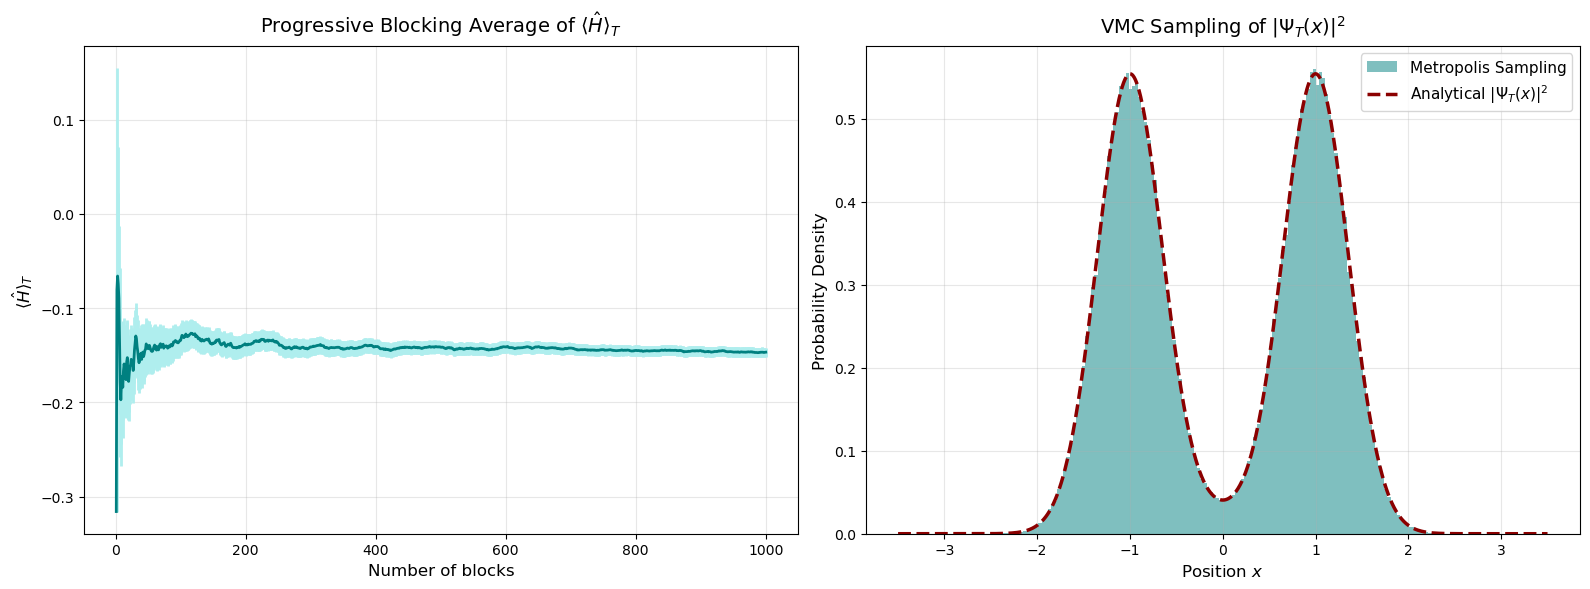

In [25]:
filepath_energy = "8.1/OUTPUT/metro_1s_unif.dat"
blocks, sum_prog, err_prog = np.loadtxt(filepath_energy, usecols=(0, 2, 3), unpack=True)

filepath_positions = "8.1/OUTPUT/positions.dat"
positions = np.loadtxt(filepath_positions)

def psi_T(x, mu, sigma):
    return np.exp(-(x - mu)**2 / (2 * sigma**2)) + np.exp(-(x + mu)**2 / (2 * sigma**2))

x_val = np.linspace(-3.5, 3.5, 1000)
mu_test = 1.0
sigma_test = 0.5
pdf_analitica = psi_T(x_val, mu_test, sigma_test)**2

norm = np.trapezoid(pdf_analitica, x_val)
pdf_analitica = pdf_analitica / norm

fig, axs = plt.subplots(1, 2, figsize=(16, 6))

# --- Subplot Sinistro: Convergenza dell'Energia ---
axs[0].errorbar(blocks, sum_prog, yerr=err_prog, fmt='-', color='teal', ecolor='paleturquoise', elinewidth=2, linewidth=2)
axs[0].set_title('Progressive Blocking Average of $\\langle \\hat{H} \\rangle_T$', fontsize=14, pad=10)
axs[0].set_xlabel('Number of blocks', fontsize=12)
axs[0].set_ylabel(r'$\langle \hat{H} \rangle_T$', fontsize=12)
axs[0].grid(True, alpha=0.3)

# --- Subplot Destro: Sampling della funzione d'onda ---
axs[1].hist(positions, bins=150, density=True, color='teal', alpha=0.5, label='Metropolis Sampling')
axs[1].plot(x_val, pdf_analitica, color='darkred', lw=2.5, linestyle='--', label=r'Analytical $|\Psi_T(x)|^2$')
axs[1].set_title(r'VMC Sampling of $|\Psi_T(x)|^2$', fontsize=14, pad=10)
axs[1].set_xlabel('Position $x$', fontsize=12)
axs[1].set_ylabel('Probability Density', fontsize=12)
axs[1].legend(fontsize=11)
axs[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The two panels confirm that the Variational Monte Carlo code is working accurately:

* **Energy Convergence (Left):** The progressive average of $\langle \hat{H} \rangle_T$ rapidly stabilizes after an initial transient, converging cleanly to $\approx -0.145$ with systematically shrinking statistical uncertainties across the 1000 blocks. In accordance with the Variational Principle, this value provides a strict upper bound to the true ground state energy ($E_0 \approx -0.460$), reflecting the unoptimized trial parameters ($\mu=1.0, \sigma=0.5$).
* **Spatial Probability Density (Right):** The normalized histogram of sampled positions matches the analytical curve $|\Psi_T(x)|^2$ without visible discrepancies, proving that the uniform Metropolis step successfully tunnels through the central barrier and samples both potential wells with proper ergodic balance.

### **8.2**
To complete the resolution of the quantum system, I extended the Variational Monte Carlo (VMC) code by implementing a Simulated Annealing (SA) algorithm to find the optimal variational parameters $\mu$ and $\sigma$ that minimize the ground state energy $\langle \hat{H} \rangle_T$. 

The algorithm exploits a thermodynamic analogy: the energy expectation value is treated as a "cost function" to minimize, and the parameter space is explored by introducing a fictitious temperature $T$. At high temperatures, the system can accept configurations with higher energy, allowing it to escape local minima; as the temperature decreases, the system progressively "freezes" toward the global minimum.

The C++ implementation is structured through the following steps:
* **Cooling Schedule:** The simulation starts from an initial temperature $T = 1.0$ and decreases exponentially by multiplying $T$ by a `cooling_rate` of $0.9$, until reaching a $T_{min} = 0.0001$.
* **Parameter Space Exploration:** At each temperature step, the algorithm proposes 100 new sets of parameters by perturbing the previous values. The step size is dynamically scaled based on the temperature ($\Delta \propto \sqrt{T}$), allowing broad exploration initially and fine-tuning as it approaches the minimum. Since the trial wavefunction is even, negative values for the parameters would merely result in redundant configurations. Therefore, taking the absolute value of the proposed moves is an algorithmic optimization chosen to halve the exploration space and avoid evaluating physically identical states.
* **Energy Evaluation and Acceptance:** For each new pair of parameters, a fast VMC simulation ($M=100000$ steps divided into $N=100$ blocks) is performed to compute the new statistical estimate of $\langle \hat{H} \rangle_T$. The move is accepted if the energy decreases ($\Delta E < 0$), or with a probability given by the Boltzmann weight $p = e^{-\Delta E / T}$.
* **High-Statistics Final Simulation:** Once the annealing process is complete, the system extracts the parameters $\mu_{opt}$ and $\sigma_{opt}$ that generated the lowest energy. With these optimal parameters, a much longer, fully thermalized final simulation ($M = 10^6$ steps) is launched to reduce statistical uncertainties on the energy and precisely sample the spatial coordinates for the probability density $|\Psi_T(x)|^2$.

Below is the analysis of the results, starting from the optimization process and concluding with the final spatial distributions.

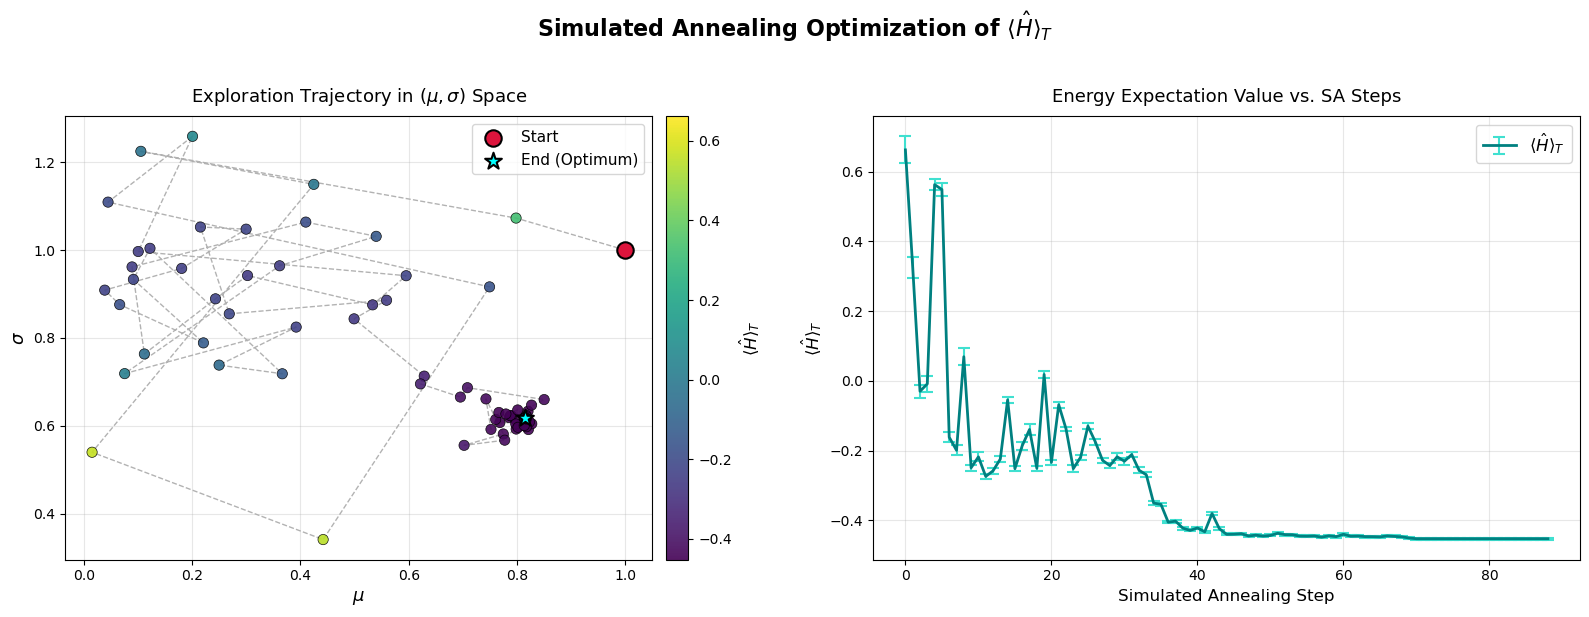

In [27]:
filepath = "8.2/OUTPUT/annealing_path.dat"
data = np.loadtxt(filepath)

temperatures = data[:, 0]
mu = data[:, 1]
sigma = data[:, 2]
energy = data[:, 3]       
error = data[:, 4]        
sa_steps = np.arange(len(energy)) 

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(r"Simulated Annealing Optimization of $\langle \hat{H} \rangle_T$", fontsize=16, fontweight='bold', y=1.02)

# ==========================================
# PANNELLO 1: Spazio dei parametri (mu, sigma)
# ==========================================
ax[0].plot(mu, sigma, color='gray', linestyle='--', linewidth=1, alpha=0.6, zorder=1)

sc = ax[0].scatter(
    mu, 
    sigma, 
    c=energy, 
    cmap='viridis', 
    s=55, 
    edgecolors='k', 
    linewidth=0.5, 
    alpha=0.9, 
    zorder=2
)

ax[0].scatter(mu[0], sigma[0], color='crimson', s=140, marker='o', edgecolors='black', linewidth=1.5, label='Start', zorder=3)
ax[0].scatter(mu[-1], sigma[-1], color='cyan', s=160, marker='*', edgecolors='black', linewidth=1.5, label='End (Optimum)', zorder=3)

cbar = fig.colorbar(sc, ax=ax[0], pad=0.02)
cbar.set_label(r'$\langle \hat{H} \rangle_T$', fontsize=12)

ax[0].set_title(r'Exploration Trajectory in $(\mu, \sigma)$ Space', fontsize=13, pad=10)
ax[0].set_xlabel(r'$\mu$', fontsize=13)
ax[0].set_ylabel(r'$\sigma$', fontsize=13)
ax[0].grid(True, alpha=0.3)
ax[0].legend(fontsize=11, loc='best')

# ==========================================
# PANNELLO 2: Energia in funzione degli step
# ==========================================
ax[1].errorbar(
    sa_steps, 
    energy, 
    yerr=error, 
    fmt='-', 
    color='teal', 
    ecolor='turquoise', 
    elinewidth=1.5, 
    linewidth=2,
    capsize=4,   
    capthick=1.5, 
    label=r'$\langle \hat{H} \rangle_T$'
)

ax[1].set_title("Energy Expectation Value vs. SA Steps", fontsize=13, pad=10)
ax[1].set_xlabel("Simulated Annealing Step", fontsize=12)
ax[1].set_ylabel(r"$\langle \hat{H} \rangle_T$", fontsize=12)
ax[1].grid(True, alpha=0.3)
ax[1].legend(fontsize=12)

plt.tight_layout()
plt.show()

The two panels illustrate the successful optimization of the variational parameters via the Simulated Annealing (SA) algorithm:

* **Parameter Space Trajectory (Left):** The algorithm begins its search at the initial parameters ($\mu=1.0, \sigma=1.0$) and broadly explores the phase space at high temperatures. As the system cools, the trajectory zeroes in on the deepest energy basin (dark purple), converging tightly around the optimal values $\mu \approx 0.81$ and $\sigma \approx 0.62$.
* **Energy Convergence (Right):** The energy expectation value $\langle \hat{H} \rangle_T$ exhibits large fluctuations during the initial high-temperature steps, allowing the system to climb out of unfavorable configurations. As the algorithm progresses and the temperature decreases, the energy smoothly and definitively plateaus towards the expected ground state minimum of approximately $-0.46$.

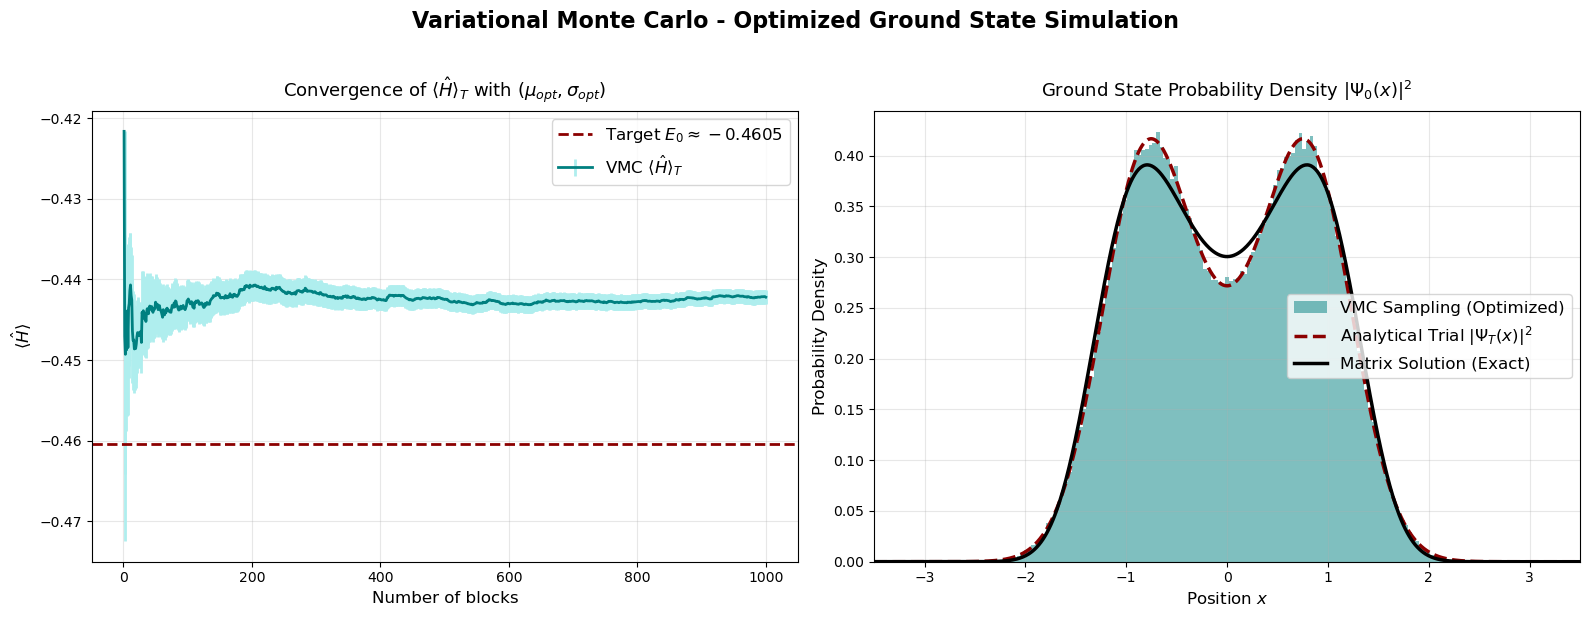

In [28]:
# Dati Energia VMC
filepath_ene = "8.2/OUTPUT/best_parameters.dat"  
blocks, sum_prog, err_prog = np.loadtxt(filepath_ene, usecols=(0, 2, 3), unpack=True)
expected_energy = -0.46046587969271513

# Dati Posizioni VMC
filepath_positions = "8.2/OUTPUT/positions.dat" 
positions = np.loadtxt(filepath_positions)

# Funzione Analitica di Prova
best_mu = 0.8148988940 
best_sigma = 0.6167595692 

def psi_T(x, mu, sigma):
    return np.exp(-(x-mu)**2/(2*sigma**2)) + np.exp(-(x+mu)**2/(2*sigma**2))

x_val = np.linspace(-3.5, 3.5, 1000)
pdf_analitica = psi_T(x_val, best_mu, best_sigma)**2
norm_analitica = np.trapezoid(pdf_analitica, x_val)
pdf_analitica = pdf_analitica / norm_analitica

# Soluzione Matriciale Esatta (Schrödinger 1D)
def Vpot(x):
    return (x**2 - 2.5)*x**2

a = 10
N = 1000 
x = np.linspace(-a/2, a/2, N)
dx = x[1] - x[0] 
V = Vpot(x)

CDiff = np.diag(np.ones(N-1),-1)-2*np.diag(np.ones(N),0)+np.diag(np.ones(N-1),1)
H = (-(0.5)*CDiff)/(dx**2) + np.diag(V)
E, psi = np.linalg.eigh(H)

psi_matrix = np.transpose(psi)
psi_sq = psi_matrix[0]**2
psi_sq_norm = psi_sq / np.trapezoid(psi_sq, x)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(r"Variational Monte Carlo - Optimized Ground State Simulation", fontsize=16, fontweight='bold', y=1.02)

# PANNELLO 1: Convergenza dell'Energia
ax[0].errorbar(
    blocks, 
    sum_prog, 
    yerr=err_prog, 
    fmt='-', 
    color='teal', 
    ecolor='paleturquoise', 
    elinewidth=2, 
    linewidth=2, 
    label=r'VMC $\langle \hat{H} \rangle_T$'
)
ax[0].axhline(
    y=expected_energy, 
    color='darkred', 
    linestyle='--', 
    linewidth=2, 
    label=f'Target $E_0 \\approx {expected_energy:.4f}$'
)

ax[0].set_title(r'Convergence of $\langle \hat{H} \rangle_T$ with ($\mu_{opt}, \sigma_{opt}$)', fontsize=13, pad=10)
ax[0].set_xlabel('Number of blocks', fontsize=12)
ax[0].set_ylabel(r'$\langle \hat{H} \rangle$', fontsize=12)
ax[0].grid(True, alpha=0.3)
ax[0].legend(fontsize=12, loc='upper right')

# PANNELLO 2: Densità di Probabilità
ax[1].hist(positions, bins=150, density=True, color='teal', alpha=0.5, label='VMC Sampling (Optimized)')
ax[1].plot(x_val, pdf_analitica, color='darkred', lw=2.5, linestyle='--', label=r'Analytical Trial $|\Psi_T(x)|^2$')
ax[1].plot(x, psi_sq_norm, color='black', lw=2.5, linestyle='-', label='Matrix Solution (Exact)')

ax[1].set_title(r"Ground State Probability Density $|\Psi_0(x)|^2$", fontsize=13, pad=10)
ax[1].set_xlim((-3.5, 3.5))
ax[1].set_xlabel('Position $x$', fontsize=12)
ax[1].set_ylabel('Probability Density', fontsize=12)
ax[1].legend(fontsize=12)
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The final high-statistics simulation using the optimized parameters ($\mu_{opt}, \sigma_{opt}$) yields the following results:

* **Energy Convergence (Left):** The variational energy $\langle \hat{H} \rangle_T$ rapidly converges with minimal statistical uncertainty. Notably, it plateaus at a value higher than the exact numerical target ($E_0 \approx -0.4605$). This is a manifestation of the **Variational Principle**: since our double-Gaussian trial wave function is only an approximation of the true ground state, its energy expectation value strictly provides an upper bound to the exact ground state energy.
* **Probability Density (Right):** The VMC spatial histogram perfectly matches the analytical trial curve $|\Psi_T(x)|^2$, confirming that the Metropolis algorithm correctly and ergodically samples the target distribution. However, a discrepancy is visible between the optimized trial function and the exact matrix solution (solid black line). The true ground state has a slightly shallower central dip and lower peaks. This subtle structural difference physically explains the energy gap observed in the left panel, as the double-Gaussian model cannot perfectly replicate the exact eigenstate of this anharmonic potential.